In [12]:
!git clone -q https://github.com/karpathy/nanoGPT.git
%cd nanoGPT
!python data/shakespeare_char/prepare.py

length of dataset in characters: 1,115,394
all the unique characters: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
vocab size: 65
train has 1,003,854 tokens
val has 111,540 tokens


In [13]:
# Making nanoGPT tell the truth about itself (CPU / Colab).
#
# part 1: every tensor shape in one training step
# part 2: checking one gradient by hand
# part 3: gradient accumulation, right vs "average of averages"
# part 4: grad norm every step, and a step where it moved before the loss
# part 5: MFU on this CPU, and where the time goes
# part 6: 0.1 in fp32, bf16 and fp8 (E4M3)

import os, math, time, pickle
from fractions import Fraction
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from model import GPT, GPTConfig          # nanoGPT's model.py, unchanged

torch.manual_seed(0)
torch.set_num_threads(os.cpu_count())

STEPS = 300     # steps per accumulation run, lower it if Colab is too slow
LR = 6e-3       # a bit high on purpose so the grad norm does something interesting

In [16]:
# ---- part 0: data and a small nanoGPT

data_dir = "data/shakespeare_char"
train_data = torch.from_numpy(np.fromfile(f"{data_dir}/train.bin", dtype=np.uint16).astype(np.int64))
val_data = torch.from_numpy(np.fromfile(f"{data_dir}/val.bin", dtype=np.uint16).astype(np.int64))
vocab_size = pickle.load(open(f"{data_dir}/meta.pkl", "rb"))["vocab_size"]  # 65

def get_batch(batch_size, seq_len, src=None):
    src = train_data if src is None else src
    ix = torch.randint(len(src) - seq_len - 1, (batch_size,))
    x = torch.stack([src[i:i + seq_len] for i in ix])
    y = torch.stack([src[i+1:i + seq_len + 1] for i in ix])  # next char at each position
    return x, y

def make_model(n_layer=4, n_head=4, n_embd=128, block_size=64):
    # dropout 0 so the forward pass is deterministic (needed for the gradient check)
    cfg = GPTConfig(block_size=block_size, vocab_size=vocab_size, n_layer=n_layer,
                    n_head=n_head, n_embd=n_embd, dropout=0.0, bias=False)
    return GPT(cfg)

start_model = make_model()
start_weights = {k: v.clone() for k, v in start_model.state_dict().items()}
N = start_model.get_num_params()  # nanoGPT leaves out wpe, keeps wte since lm_head reuses it

def show(name, t, meaning):
    print(f" {name:<16} {str(tuple(t.shape)):<18} {meaning}")

number of parameters: 0.80M


In [17]:
# ---- part 1: every tensor shape in one step[cite: 2]
# nanoGPT's forward() doesn't expose q, k, v or the attention matrix, so this walks[cite: 2]
# through the same modules by hand, printing as it goes. at the end it checks the[cite: 2]
# result against model(x) so we know the walk-through matches the real thing.[cite: 2]

def traced_forward(model, idx):
    tf = model.transformer
    B, T = idx.shape
    show("idx", idx, "batch, position (char ids)")

    tok = tf.wte(idx)
    show("wte(idx)", tok, "batch, position, embedding feature")
    pos = tf.wpe(torch.arange(T))
    show("wpe(pos)", pos, "position, feature (shared by every sequence)")
    x = tf.drop(tok + pos)

    blk = tf.h[0]
    attn = blk.attn
    C = x.size(-1)
    hs = C // attn.n_head

    h = blk.ln_1(x)
    show("ln_1(x)", h, "batch, position, feature normalised per token")
    qkv = attn.c_attn(h)
    show("c_attn(h)", qkv, "batch, position, 3*C = query | key | value")
    q, k, v = qkv.split(C, dim=2)
    q = q.view(B, T, attn.n_head, hs).transpose(1, 2)
    k = k.view(B, T, attn.n_head, hs).transpose(1, 2)
    v = v.view(B, T, attn.n_head, hs).transpose(1, 2)
    show("q / k / v", q, "batch, head, position, feature within the head")

    att = q @ k.transpose(-2, -1) / math.sqrt(hs)
    show("q @ k^T", att, "batch, head, query position, key position")
    mask = torch.tril(torch.ones(T, T)).bool()
    att = F.softmax(att.masked_fill(~mask, float("-inf")), dim=-1)
    show("softmax", att, "same; rows sum to 1, zero above the diagonal")

    y = att @ v
    show("att @ v", y, "batch, head, position, mixed value features")
    y = y.transpose(1, 2).contiguous().view(B, T, C)
    show("heads joined", y, "batch, position, heads glued back into C")
    x = x + attn.c_proj(y)
    show("x + attn", x, "batch, position, residual stream")

    hid = blk.mlp.gelu(blk.mlp.c_fc(blk.ln_2(x)))
    show("mlp hidden", hid, "batch, position, 4*C hidden units")
    x = x + blk.mlp.c_proj(hid)
    show("x + mlp", x, "batch, position, residual stream leaving block 0")

    for b in tf.h[1:]:
        x = b(x)
    print("  (blocks 1..3 have the same shapes)")
    x = tf.ln_f(x)
    logits = model.lm_head(x)
    show("logits", logits, f"batch, position, score for each of {vocab_size} chars")
    return logits

print("--- part 1: shapes in one training step (B=3, T=10, C=128, 4 heads of 32) ---")
model = make_model()
model.load_state_dict(start_weights)
opt = model.configure_optimizers(0.1, 1e-3, (0.9, 0.95), "cpu")
x, y = get_batch(3, 10)

print("forward:")
logits = traced_forward(model, x)
real_logits, loss = model(x, y)
print(f"  matches nanoGPT's own forward? max difference {(logits - real_logits).abs().max():.2e}")
show("targets", y, "batch, position (id of the next char)")
show("logits.view", logits.view(-1, vocab_size), "every token as its own classification, classes")
show("loss", loss, "scalar: mean cross-entropy over 30 tokens")

print("backward:")
loss.backward()
show("wte.grad", model.transformer.wte.weight.grad,
     "vocab entry, feature (gets gradient from the input AND lm_head, same tensor)")
show("wpe.grad", model.transformer.wpe.weight.grad, "position (block_size), feature")
show("c_attn.grad", model.transformer.h[0].attn.c_attn.weight.grad, "output 3*C, input C")
show("c_fc.grad", model.transformer.h[0].mlp.c_fc.weight.grad, "output 4*C, input C")
show("ln_1.grad", model.transformer.h[0].ln_1.weight.grad, "one scale per feature")

print("optimizer step:")
opt.step()
st = opt.state[model.transformer.h[0].attn.c_attn.weight]
show("exp_avg", st["exp_avg"], "same as weight: running mean of the gradient")
show("exp_avg_sq", st["exp_avg_sq"], "same as weight: running mean of gradient squared")
show("step", st["step"], "scalar: number of updates so far")
print(f"non-embedding params (nanoGPT's count): {N:,}")

--- part 1: shapes in one training step (B=3, T=10, C=128, 4 heads of 32) ---
number of parameters: 0.80M
num decayed parameter tensors: 18, with 802,944 parameters
num non-decayed parameter tensors: 9, with 1,152 parameters
using fused AdamW: False
forward:
 idx              (3, 10)            batch, position (char ids)
 wte(idx)         (3, 10, 128)       batch, position, embedding feature
 wpe(pos)         (10, 128)          position, feature (shared by every sequence)
 ln_1(x)          (3, 10, 128)       batch, position, feature normalised per token
 c_attn(h)        (3, 10, 384)       batch, position, 3*C = query | key | value
 q / k / v        (3, 4, 10, 32)     batch, head, position, feature within the head
 q @ k^T          (3, 4, 10, 10)     batch, head, query position, key position
 softmax          (3, 4, 10, 10)     same; rows sum to 1, zero above the diagonal
 att @ v          (3, 4, 10, 32)     batch, head, position, mixed value features
 heads joined     (3, 10, 128)    

In [19]:
#------- part 2: one gradient by hand
#nudge one weight of c_attn up and down by eps, and compare (L+-L-)/2eps
# with the number backward() put in .grad

print("\n--- part 2: finite difference vs backward() ---")

def check_gradient(dtype, row=3, col=5):
    m = make_model()
    m.load_state_dict(start_weights)
    m = m.to(dtype).eval()
    torch.manual_seed(123)
    x, y = get_batch(4, 32)

    m.zero_grad()
    m(x, y)[1].backward()
    w = m.transformer.h[0].attn.c_attn.weight
    from_backward = w.grad[row, col].item()
    print(f"\n{dtype}: backward() says {from_backward:+.12f}")
    print(f" {'eps':>6} {'numeric':>16} {'rel error':>10}")

    with torch.no_grad():
        original = w[row, col].item()
        for eps in [1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-8]:
            w[row, col] = original + eps
            up = m(x, y)[1].item()
            w[row, col] = original - eps
            down = m(x, y)[1].item()
            w[row, col] = original
            numeric = (up - down) / (2 * eps)
            rel = abs(numeric - from_backward) / abs(from_backward)
            print(f" {eps:6.0e} {numeric:+16.12f} {rel:10.2e}")

check_gradient(torch.float64)
check_gradient(torch.float32)
# float64 should agree to many decimals. float32 gets better and then worse again:
# the loss is about 4 and float32 can only see changes of ~5e-7 at that size, so a
# tiny eps turns rounding into a big error. at eps=1e-8 both losses are identical and
# the "gradient" comes out 0. backward() is fine; the measurement is what fails.


--- part 2: finite difference vs backward() ---
number of parameters: 0.80M

torch.float64: backward() says -0.000073460783
    eps          numeric  rel error
  1e-01  -0.000073460549   3.18e-06
  1e-02  -0.000073460781   3.16e-08
  1e-03  -0.000073460783   4.10e-10
  1e-04  -0.000073460780   4.80e-08
  1e-05  -0.000073460793   1.33e-07
  1e-06  -0.000073460793   1.33e-07
  1e-08  -0.000073452355   1.15e-04
number of parameters: 0.80M

torch.float32: backward() says -0.000073460746
    eps          numeric  rel error
  1e-01  -0.000071525574   2.63e-02
  1e-02  -0.000095367432   2.98e-01
  1e-03  +0.000000000000   1.00e+00
  1e-04  +0.000000000000   1.00e+00
  1e-05  +0.000000000000   1.00e+00
  1e-06  +0.000000000000   1.00e+00
  1e-08  +0.000000000000   1.00e+00



--- part 3: gradient accumulation ---
short-context tokens 384, long-context tokens 1024
right: short tokens carry 27% of the gradient
wrong: short tokens carry 75% (each micro-batch counts 1/4 no matter its size)
number of parameters: 0.80M
right vs one big batch: rel diff 1.21e-07, cosine 1.000048
wrong vs one big batch: rel diff 4.76e-01, cosine 0.919538
number of parameters: 0.80M
num decayed parameter tensors: 18, with 802,944 parameters
num non-decayed parameter tensors: 9, with 1,152 parameters
using fused AdamW: False
[right] step   0 loss 4.2279 grad norm 3.622 val 3.9065
[right] step  25 loss 2.7412 grad norm 0.720 val 2.7020
[right] step  50 loss 2.6085 grad norm 0.672 val 2.6077
[right] step  75 loss 2.6262 grad norm 0.643 val 2.5659
[right] step 100 loss 2.4562 grad norm 0.430 val 2.5400
[right] step 125 loss 2.4651 grad norm 0.517 val 2.4698
[right] step 150 loss 2.4106 grad norm 0.455 val 2.3752
[right] step 175 loss 2.3789 grad norm 0.504 val 2.3403
[right] step 200 lo

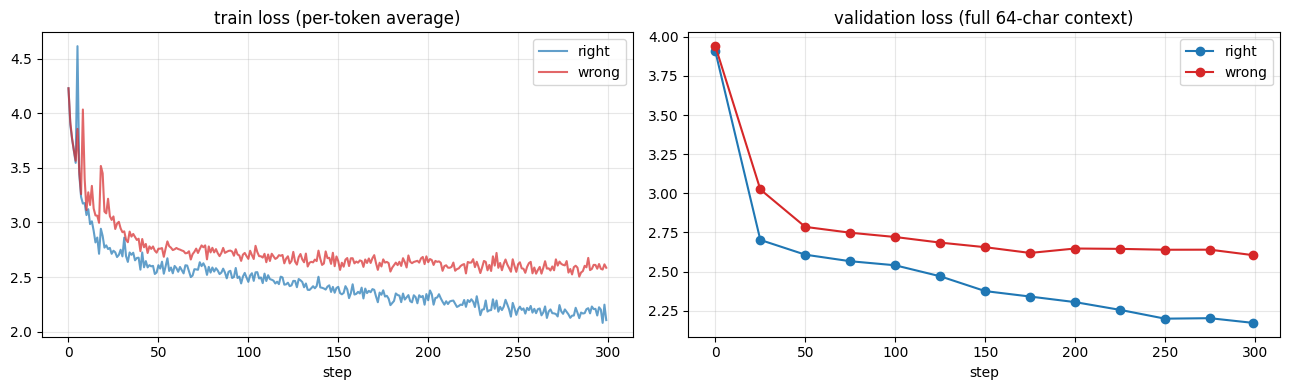

final val gap (wrong - right): +0.4327


In [31]:
#---- part 3: gradient accumulation, right vs wrong
# nanoGPT's train.py does loss / gradient_accumulation_steps, i.e. the average of the
# per-micro-batch averages. that's only right when every micro-batch has the same
# number of tokens. here three micro-batches are 8 chars long and one is 64.

print("\n--- part 3: gradient accumulation ---")
LENGTHS = [8, 8, 8, 64]
SEQS = 16
short, long_ = 3 * 8 * SEQS, 64 * SEQS
print(f"short-context tokens {short}, long-context tokens {long_}")
print(f"right: short tokens carry {100 * short / (short + long_):.0f}% of the gradient")
print(f"wrong: short tokens carry 75% (each micro-batch counts 1/4 no matter its size)")

def accumulate(model, micro, mode):
    model.zero_grad(set_to_none=True)
    total_tokens = sum(y.numel() for _, y in micro)
    total_loss = 0.0
    for x, y in micro:
        logits, _ = model(x, y)
# Accumulate the total loss sum across valid tokens only.
# 'reduction="sum"' combined with 'ignore_index' ensures that when we subsequently
# divide by the total valid token count across all micro-batches, we achieve exact
# mathematical equivalence to a single unpadded macro-batch.
        loss_sum = F.cross_entropy(logits.view(-1, vocab_size), y.view(-1), reduction="sum",ignore_index=-1)
        if mode == "right":
            loss = loss_sum / total_tokens
        else:
            loss = (loss_sum / y.numel()) / len(micro)  # what train.py does
        loss.backward()
        total_loss += loss_sum.item()
    return total_loss / total_tokens  # same metric for both runs

# sanity check: "right" should equal one big padded batch, "wrong" shouldn't.
# nanoGPT ignores targets equal to -1, so pad the targets with -1.
m = make_model()
m.load_state_dict(start_weights)
micro = [get_batch(SEQS, n) for n in LENGTHS]
flat = lambda: torch.cat([p.grad.flatten() for p in m.parameters()])

accumulate(m, micro, "right"); g_right = flat()
accumulate(m, micro, "wrong"); g_wrong = flat()
big_x = torch.cat([F.pad(x, (0, 64 - x.shape[1])) for x, _ in micro])
big_y = torch.cat([F.pad(y, (0, 64 - y.shape[1]), value=-1) for _, y in micro])
m.zero_grad()
m(big_x, big_y)[1].backward()
g_big = flat()
for name, g in [("right", g_right), ("wrong", g_wrong)]:
    print(f"{name} vs one big batch: rel diff {(g - g_big).norm() / g_big.norm():.2e}, "
          f"cosine {F.cosine_similarity(g, g_big, dim=0):.6f}")

@torch.no_grad()
def val_loss(model):
    model.eval()
    g = torch.Generator().manual_seed(42)
    total = 0.0
    for _ in range(5):
        ix = torch.randint(len(val_data) - 65, (32,), generator=g)
        x = torch.stack([val_data[i:i + 64] for i in ix])
        y = torch.stack([val_data[i + 1:i + 65] for i in ix])
        total += model(x, y)[1].item()
    model.train()
    return total / 5

def flops_per_token(model, T):
    # same formula as nanoGPT's estimate_mfu: 6N + 12 * layers * C * T
    c = model.config
    return 6 * model.get_num_params() + 12 * c.n_layer * c.n_embd * T

def train(mode):
    torch.manual_seed(1)  # both runs see identical batches
    model = make_model()
    model.load_state_dict(start_weights)
    opt = model.configure_optimizers(0.1, LR, (0.9, 0.95), "cpu")
    hist = {"loss": [], "grad_norm": [], "val": [], "time": [], "flops": []}

    for step in range(STEPS):
        for group in opt.param_groups:
            group["lr"] = LR * min(1.0, (step + 1) / 30)
        micro = [get_batch(SEQS, n) for n in LENGTHS]

        t0 = time.perf_counter()
        loss = accumulate(model, micro, mode)
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0).item()  # norm before clipping
        opt.step()
        hist["time"].append(time.perf_counter() - t0)

        hist["loss"].append(loss)
        hist["grad_norm"].append(grad_norm)
        hist["flops"].append(sum(y.numel() * flops_per_token(model, y.shape[1]) for _, y in micro))
        if step % 25 == 0 or step == STEPS - 1:
            v = val_loss(model)
            hist["val"].append((step, v))
            print(f"[{mode}] step {step:3d} loss {loss:.4f} grad norm {grad_norm:.3f} val {v:.4f}")
    return hist

runs = {"right": train("right"), "wrong": train("wrong")}

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for mode, color in [("right", "tab:blue"), ("wrong", "tab:red")]:
    ax[0].plot(runs[mode]["loss"], color=color, alpha=0.7, label=mode)
    s, v = zip(*runs[mode]["val"])
    ax[1].plot(s, v, "o-", color=color, label=mode)
ax[0].set_title("train loss (per-token average)")
ax[1].set_title("validation loss (full 64-char context)")
for a in ax:
    a.set_xlabel("step"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("accumulation.png", dpi=120); plt.show()
print(f"final val gap (wrong - right): {runs['wrong']['val'][-1][1] - runs['right']['val'][-1][1]:+.4f}")


--- part 4: grad norm vs loss ---
no clear case this run; biggest grad norm jump is at step 190. try LR = 6e-3 or 1e-2.


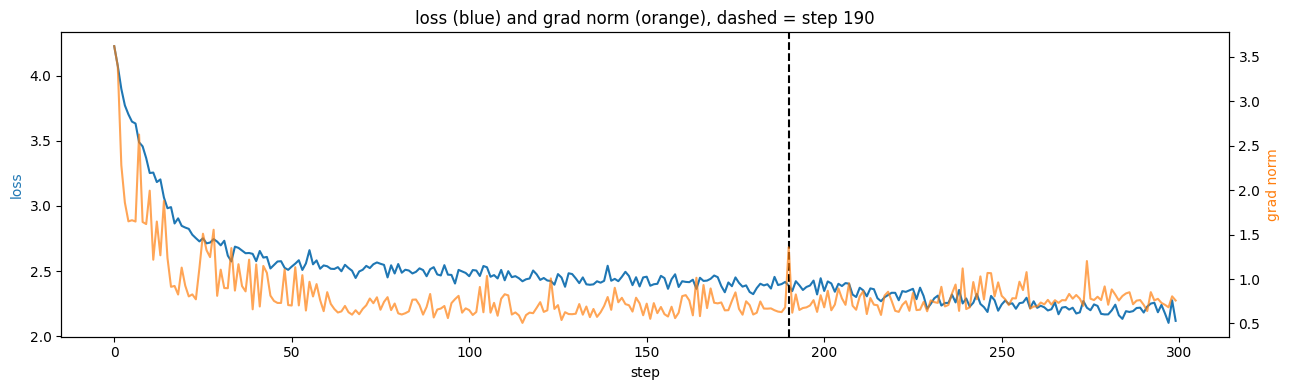

In [25]:
# ---- part 4: grad norm moving before the loss
# the loss and grad norm at step t come from the same forward pass, so a big gradient
# can't show up in the loss until the optimizer has applied it. looking for a step
# where the norm jumps, the loss is still flat, and the loss rises right after.

print("\n--- part 4: grad norm vs loss ---")
gn, ls = runs["right"]["grad_norm"], runs["right"]["loss"]
WINDOW, JUMP, AHEAD = 20, 2.0, 5

found = None
for t in range(WINDOW, len(gn) - AHEAD):
    median_gn = sorted(gn[t - WINDOW:t])[WINDOW // 2]
    mean_loss = sum(ls[t - WINDOW:t]) / WINDOW
    if gn[t] > JUMP * median_gn and ls[t] - mean_loss < 0.02 \
       and max(ls[t + 1:t + 1 + AHEAD]) - mean_loss > 0.05:
        found = t
        break

if found is not None:
    t = found
    print(f"step {t}: grad norm jumped, loss flat, loss rose afterwards")
    for s in range(t - 3, t + AHEAD + 1):
        print(f" step {s:3d} grad norm {gn[s]:7.3f} loss {ls[s]:.4f}" + (" <- norm moves" if s == t else ""))
else:
    t = max(range(WINDOW, len(gn)), key=lambda i: gn[i] / sorted(gn[i - WINDOW:i])[WINDOW // 2])
    print(f"no clear case this run; biggest grad norm jump is at step {t}. try LR = 6e-3 or 1e-2.")

fig, a1 = plt.subplots(figsize=(13, 4)); a2 = a1.twinx()
a1.plot(ls, color="tab:blue"); a2.plot(gn, color="tab:orange", alpha=0.7)
a1.axvline(t, color="black", linestyle="--")
a1.set_xlabel("step"); a1.set_ylabel("loss", color="tab:blue"); a2.set_ylabel("grad norm", color="tab:orange")
plt.title(f"loss (blue) and grad norm (orange), dashed = step {t}")
plt.tight_layout(); plt.savefig("grad_norm.png", dpi=120); plt.show()


--- part 4: grad norm vs loss ---
number of parameters: 0.80M
num decayed parameter tensors: 18, with 802,944 parameters
num non-decayed parameter tensors: 9, with 1,152 parameters
using fused AdamW: False
lr 0.01: found a lead at step 339
 step 336 grad norm    0.655 probe loss 2.7060
 step 337 grad norm    0.673 probe loss 2.7111
 step 338 grad norm    0.590 probe loss 2.7219
 step 339 grad norm    1.053 probe loss 2.7128  <- grad norm moves, loss hasn't yet
 step 340 grad norm    0.528 probe loss 2.7237
 step 341 grad norm    0.579 probe loss 2.7372
 step 342 grad norm    0.390 probe loss 2.7360
 step 343 grad norm    0.635 probe loss 2.7401
 step 344 grad norm    0.331 probe loss 2.7232
 step 345 grad norm    0.459 probe loss 2.7109

correlation of |change in grad norm| at t with |change in loss| at t+lag:
 lag 0: +0.919
 lag 1: +0.581
 lag 2: +0.133
 lag 3: +0.152
 lag 4: +0.286
 lag 5: +0.384


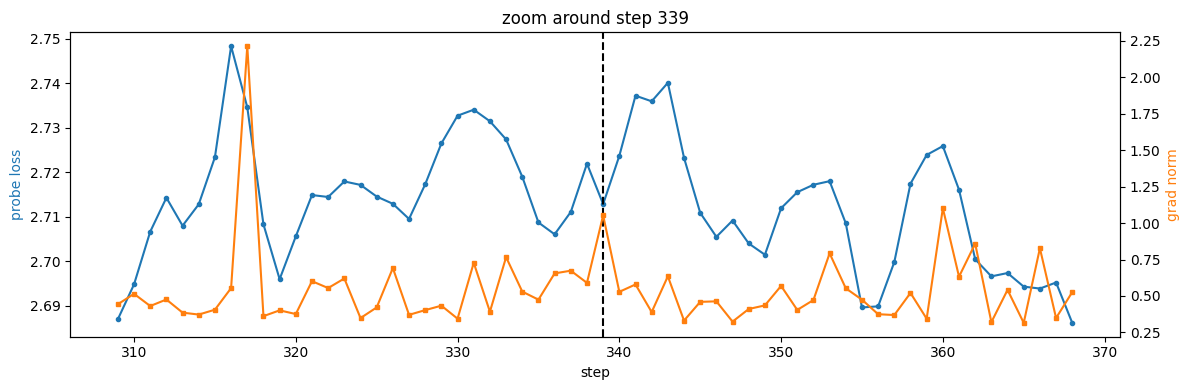

In [28]:
### above experiment did not work for grad norm so trying again with few chnages in optimizer
# ---- part 4 (redone): grad norm moving before the loss
#
# my first attempt didn't work, for four reasons:
# - grad norm and loss at step t came from the same random batch, so a hard batch
#   pushed both up together, and my "loss stays flat" rule threw those steps away
# - the loss jumps around a lot from batch to batch anyway, which hides small changes
# - clipping at 1.0 and AdamW's normalisation mean a big gradient doesn't make a big step
# - early on the loss is falling fast, so comparing to a trailing average is misleading
#
# what's different now:
# - the loss is measured on ONE fixed probe batch every step, before the update.
# - it can only change when the weights change, so it isn't affected by which batch we drew.
# - no clipping, beta2 = 0.99 and a high lr, so Adam can actually overshoot
# - "moved" means compared to how much the probe loss normally moves per step

import statistics

print("\n--- part 4: grad norm vs loss ---")
torch.manual_seed(999)
PROBE_X, PROBE_Y = get_batch(64, 64, val_data)  # same batch every step

def spike_run(lr, steps=400, beta2=0.99):
    torch.manual_seed(0)
    model = make_model()
    model.load_state_dict(start_weights)
    opt = model.configure_optimizers(0.0, lr, (0.9, beta2), "cpu")
    probe_loss, grad_norm = [], []

    for step in range(steps):
        for g in opt.param_groups:
            g["lr"] = lr * min(1.0, (step + 1) / 10)

        # loss on the fixed batch, with the weights we're about to update
        model.eval()
        with torch.no_grad():
            probe_loss.append(model(PROBE_X, PROBE_Y)[1].item())
        model.train()

        x, y = get_batch(16, 64)
        _, loss = model(x, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        # max_norm=inf means nothing gets clipped; we only want the number
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), float("inf")).item()
        grad_norm.append(gn)
        opt.step()

    return probe_loss, grad_norm


def find_lead(probe, gn, window=20, ahead=5):
    for t in range(window, len(gn) - ahead):
        usual_gn = statistics.median(gn[t - window:t])
        recent = probe[t - window:t]
        usual_move = statistics.median(abs(b - a) for a, b in zip(recent, recent[1:])) + 1e-8

        loss_now = probe[t] - probe[t - 1]
        loss_after = max(probe[t + 1:t + 1 + ahead]) - probe[t]  # does it move afterwards?
        if gn[t] > 2 * usual_gn and loss_now < 2 * usual_move and loss_after > 5 * usual_move:
            return t
    return None

found, probe, gn = None, None, None
for lr in [1e-2, 2e-2, 3e-2]:
    probe, gn = spike_run(lr)
    found = find_lead(probe, gn)
    print(f"lr {lr:g}: " + (f"found a lead at step {found}" if found is not None else "no clear case"))
    if found is not None:
        break

if found is not None:
    t = found
    for s in range(t - 3, t + 7):
        mark = "  <- grad norm moves, loss hasn't yet" if s == t else ""
        print(f" step {s:3d} grad norm {gn[s]:8.3f} probe loss {probe[s]:.4f}{mark}")
else:
    t = max(range(20, len(gn)), key=lambda i: gn[i] / statistics.median(gn[i - 20:i]))
    print(f"still no clean case; biggest relative grad norm jump is at step {t}")

# averaged over the whole run: does a change in grad norm now line up with a change
# in loss later? a peak at a positive lag means the grad norm tends to lead.
dg = torch.tensor(gn).diff().abs()
d1 = torch.tensor(probe).diff().abs()
print("\ncorrelation of |change in grad norm| at t with |change in loss| at t+lag:")
for lag in range(0, 6):
    a = dg[:-lag] if lag > 0 else dg
    b = d1[lag:]
    print(f" lag {lag}: {torch.corrcoef(torch.stack([a, b]))[0, 1]:+.3f}")

lo, hi = max(0, t - 30), min(len(gn), t + 30)
fig, a1 = plt.subplots(figsize=(12, 4))
a2 = a1.twinx()
a1.plot(range(lo, hi), probe[lo:hi], "o-", color="tab:blue", ms=3)
a2.plot(range(lo, hi), gn[lo:hi], "s-", color="tab:orange", ms=3)
a1.axvline(t, color="black", linestyle="--")
a1.set_xlabel("step")
a1.set_ylabel("probe loss", color="tab:blue")
a2.set_ylabel("grad norm", color="tab:orange")
plt.title(f"zoom around step {t}")
plt.tight_layout()
plt.savefig("grad_norm.png", dpi=120)
plt.show()

In [29]:
# ---- part 5: MFU on this CPU
# nanoGPT's estimate_mfu() divides by 312 TFLOPS (an A100), which is meaningless here.
# so: peak = physical cores * clock * fp32 FLOPS per cycle, read from /proc/cpuinfo.

print("\n--- part 5: MFU ---")
info = open("/proc/cpuinfo").read()
lines = info.splitlines()
cpu_name = next(l for l in lines if l.startswith("model name")).split(":")[1].strip()
flags = next(l for l in lines if l.startswith("flags"))
ghz = float(next(l for l in lines if l.startswith("cpu MHz")).split(":")[1]) / 1000
cores = max(1, os.cpu_count() // 2)     # colab vCPUs are hyperthread pairs
per_cycle = 64 if "avx512f" in flags else 32 if "avx2" in flags else 16  # 2 FMA units
peak = cores * ghz * 1e9 * per_cycle
print(f"cpu: {cpu_name}")
print(f"{cores} core(s) x {ghz:.2f} GHz x {per_cycle} FLOPS/cycle = {peak / 1e9:.1f} GFLOP/s peak")

a, b = torch.randn(2048, 2048), torch.randn(2048, 2048)
a @ b
t0 = time.perf_counter()
for _ in range(5):
    a @ b
best = 5 * 2 * 2048 ** 3 / (time.perf_counter() - t0)
print(f"one big matmul reaches {best / 1e9:.1f} GFLOP/s ({100 * best / peak:.0f}% of peak)")

r = runs["right"]
mine = sum(r["flops"][10:]) / sum(r["time"][10:])
print(f"\nmy training loop: {mine / 1e9:.2f} GFLOP/s -> MFU {100 * mine / peak:.1f}% "
      f"({100 * mine / best:.1f}% of the big matmul)")

def benchmark(n_layer, n_head, n_embed, B, T, iters=10):
    m = make_model(n_layer, n_head, n_embed, T)
    o = m.configure_optimizers(0.1, 1e-4, (0.9, 0.95), "cpu")
    x, y = get_batch(B, T)
    for i in range(iters + 2):
        if i == 2:
            t0 = time.perf_counter()
        m(x, y)[1].backward(); o.step(); o.zero_grad(set_to_none=True)
    return B * T * flops_per_token(m, T) / ((time.perf_counter() - t0) / iters)

print("\nsame nanoGPT code, different shapes:")
for label, cfg in [("fixed batch 16x64, no logging", (4, 4, 128, 16, 64)),
                   ("bigger batch 64x64", (4, 4, 128, 64, 64)),
                   ("wider model n_embed=384", (4, 6, 384, 16, 64))]:
    f = benchmark(*cfg)
    print(f" {label:<32} {f / 1e9:6.2f} GFLOP/s MFU {100 * f / peak:5.1f}%")

from torch.profiler import profile, ProfilerActivity
m = make_model()
o = m.configure_optimizers(0.1, 1e-4, (0.9, 0.95), "cpu")
x, y = get_batch(16, 64)
with profile(activities=[ProfilerActivity.CPU]) as prof:
    m(x, y)[1].backward(); o.step(); o.zero_grad()
print(prof.key_averages().table(sort_by="self_cpu_time_total", row_limit=12))

# what I think is costing the distance to 40% (check against the numbers above):
# - n_embed=128 makes every matmul small, so the CPU spends its time moving data
#   rather than multiplying. the "wider model" row should show the difference.
# - layernorm, gelu, softmax, the residual adds and AdamW all take time but count
#   as zero model FLOPS. look for them in the profiler table.
# - per-op overhead in pytorch: with tensors this small, dispatching an op costs
#   about as much as running it.
# - the three 8-char micro-batches pay the full overhead for very little work.
# - the peak is optimistic: it assumes both FMA units busy every cycle at full clock,
#   and two colab vCPUs share one physical core.


--- part 5: MFU ---
cpu: Intel(R) Xeon(R) CPU @ 2.20GHz
1 core(s) x 2.20 GHz x 32 FLOPS/cycle = 70.4 GFLOP/s peak
one big matmul reaches 73.5 GFLOP/s (104% of peak)

my training loop: 32.63 GFLOP/s -> MFU 46.3% (44.4% of the big matmul)

same nanoGPT code, different shapes:
number of parameters: 0.80M
num decayed parameter tensors: 18, with 802,944 parameters
num non-decayed parameter tensors: 9, with 1,152 parameters
using fused AdamW: False
 fixed batch 16x64, no logging     42.44 GFLOP/s MFU  60.3%
number of parameters: 0.80M
num decayed parameter tensors: 18, with 802,944 parameters
num non-decayed parameter tensors: 9, with 1,152 parameters
using fused AdamW: False
 bigger batch 64x64                47.64 GFLOP/s MFU  67.7%
number of parameters: 7.11M
num decayed parameter tensors: 18, with 7,127,424 parameters
num non-decayed parameter tensors: 9, with 3,456 parameters
using fused AdamW: False
 wider model n_embed=384           53.12 GFLOP/s MFU  75.5%
number of parameters: 0.80

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                               aten::mm        58.98%      73.351ms        59.02%      73.401ms       1.439ms            51  
aten::_scaled_dot_product_flash_attention_for_cpu_ba...         6.32%       7.863ms         6.98%       8.676ms       2.169ms             4  
      aten::_scaled_dot_product_flash_attention_for_cpu         4.74%       5.895ms         4.87%       6.061ms       1.515ms             4  
                                    aten::gelu_backward         3.93%       4.891ms         3.93%       4.891ms       1.223ms             4  
      

In [30]:
# ---- part 6: 0.1 in fp32, bf16 and fp8 (E4M3)
# 0.1 = 1.6 * 2^-4 and 1.6 in binary is 1.1001100110011... forever, so it's never exact.
# encode() rounds by hand (to nearest, ties to even); then we compare with torch's bits.

print("\n--- part 6: 0.1 in bits ---")

def encode(value, exp_bits, man_bits, bias):
    e = 0
    while Fraction(2) ** e > value: e -= 1
    while Fraction(2) ** (e + 1) <= value: e += 1
    frac = (value / Fraction(2) ** e - 1) * 2 ** man_bits
    m = frac.numerator // frac.denominator
    rest = frac - m
    if rest > Fraction(1, 2) or (rest == Fraction(1, 2) and m % 2 == 1):
        m += 1
    if m == 2 ** man_bits:
        m, e = 0, e + 1
    stored = (1 + Fraction(m, 2 ** man_bits)) * Fraction(2) ** e
    return "0", format(e + bias, f"0{exp_bits}b"), format(m, f"0{man_bits}b"), stored

def torch_bits(t):
    n = t.element_size() * 8
    as_int = {32: torch.int32, 16: torch.int16, 8: torch.uint8}[n]
    return format(t.view(as_int).item() & ((1 << n) - 1), f"0{n}b")

for name, eb, mb, bias, dtype in [("fp32", 8, 23, 127, torch.float32),
                                   ("bf16", 8, 7, 127, torch.bfloat16),
                                   ("fp8 e4m3", 4, 3, 7, getattr(torch, "float8_e4m3fn", None))]:
    s, e, m, stored = encode(Fraction(1, 10), eb, mb, bias)
    err = float(stored - Fraction(1, 10))
    print(f"{name:9} {s} | {e} | {m}")
    print(f"            exponent {int(e, 2)} - {bias} = {int(e, 2) - bias}, value {float(stored):.12g}, "
          f"error {err:+.2e} ({100 * err / 0.1:+.4f}%)")
    if dtype is not None:
        tb = torch_bits(torch.tensor(0.1, dtype=torch.float64).to(dtype))
        print(f"            torch gives {tb} -> {'same' if tb == s + e + m else 'different!'}")

# I'd train in bf16 for the matmuls with fp32 weights and optimizer state (what nanoGPT
# does on GPU with dtype='bfloat16'). bf16 keeps fp32's 8 exponent bits, so same range
# and no loss scaling; 0.1% error is small next to SGD noise. weights stay fp32 because
# small updates vanish in bf16:
bf = torch.tensor(0.1).bfloat16()
print(f"bf16(0.1) + 1e-5 == bf16(0.1)?", bool(bf + torch.tensor(1e-5).bfloat16() == bf))
# True: bf16 numbers near 0.1 are ~0.0005 apart, so the update rounds away.
# fp8 is 1.6% off on one number and tops out at 448: only for scaled matmul inputs on big
# models. on this CPU I trained in plain fp32, since CPUs gain little from bf16.


--- part 6: 0.1 in bits ---
fp32      0 | 01111011 | 10011001100110011001101
            exponent 123 - 127 = -4, value 0.10000000149, error +1.49e-09 (+0.0000%)
            torch gives 00111101110011001100110011001101 -> same
bf16      0 | 01111011 | 1001101
            exponent 123 - 127 = -4, value 0.10009765625, error +9.77e-05 (+0.0977%)
            torch gives 0011110111001101 -> same
fp8 e4m3  0 | 0011 | 101
            exponent 3 - 7 = -4, value 0.1015625, error +1.56e-03 (+1.5625%)
            torch gives 00011101 -> same
bf16(0.1) + 1e-5 == bf16(0.1)? True
